# Natural-Scene Image Classification with a Residual CNN + Grad-CAM

**Dataset:** Intel Image Classification (6 scene classes, 150×150 RGB) | **Architecture:** custom residual CNN (4 blocks, Functional API)

**Author:** Mohammad Aqel

> Colab: Runtime → Change runtime type → T4 GPU → Run all (~30–60 min). Figures save as PNG.

## 1. Environment Setup, Hardware Acceleration & Pipeline Mechanics
### 1(a) Libraries and GPU check
TensorFlow/Keras (model), NumPy/Pandas (data), Matplotlib/Seaborn (plots), Scikit-learn (metrics/split). Seeds fixed for reproducibility. GPU availability is verified below and training runs on it if present.

In [1]:
import os, random, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow  :", tf.__version__)
print("Keras       :", keras.__version__)
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("Scikit-Learn:", sklearn.__version__)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
print("\nGlobal random seed fixed to", SEED)

TensorFlow  : 2.20.0
Keras       : 3.13.2
NumPy       : 2.0.2
Pandas      : 2.2.2
Scikit-Learn: 1.6.1

Global random seed fixed to 42


In [2]:
# --- Systematic GPU verification -------------------------------------------
gpus = tf.config.list_physical_devices("GPU")
print(f"Number of GPUs detected by TensorFlow: {len(gpus)}")

if gpus:
    for gpu in gpus:
        print("Logical device :", gpu)
        details = tf.config.experimental.get_device_details(gpu)
        print("  Device name        :", details.get("device_name", "N/A"))
        print("  Compute capability :", details.get("compute_capability", "N/A"))
    print("TF built with CUDA :", tf.test.is_built_with_cuda())
    # Full hardware report from the NVIDIA driver:
    !nvidia-smi
else:
    print("WARNING: no GPU visible - training will fall back to the CPU.")
    print("In Colab: Runtime -> Change runtime type -> Hardware accelerator -> GPU")

DEVICE = "/GPU:0" if gpus else "/CPU:0"
print("\nAll training will run on:", DEVICE)

Number of GPUs detected by TensorFlow: 1
Logical device : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
  Device name        : Tesla T4
  Compute capability : (7, 5)
TF built with CUDA : True
Thu Jul 16 09:35:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8    

### 1(b) Python generator/NumPy vs. `tf.data` pipeline
A Python generator prepares one batch at a time on a single thread (GIL-bound): the GPU sits idle while the next batch is decoded from disk, so epoch time ≈ I/O time + compute time, and every epoch repeats the same disk reads/decodes.

`tf.data` fixes this with three primitives:
- **`.map(..., num_parallel_calls=AUTOTUNE)`** — decodes/resizes on multiple CPU threads (bypasses the GIL).
- **`.cache()`** — stores decoded tensors after epoch 1, skipping repeated disk I/O.
- **`.prefetch(AUTOTUNE)`** — a background thread prepares batch *t+1* while the GPU computes batch *t*, so epoch time ≈ max(prep, compute) instead of their sum.

Net effect: near-100% GPU utilisation vs. a starved GPU with a generator, typically 2–5× faster epochs. Section 2(c) builds the pipeline with these primitives, with augmentation applied to the training stream only.

## 2. Dataset Ingestion & Pipeline Engineering
### 2(a) Dataset: Intel Image Classification
~25,000 RGB scene photos, 150×150, 6 classes: buildings, forest, glacier, mountain, sea, street. Satisfies the "high-complexity" requirement via resolution (150×150, vs 32×32 in banned datasets) and class overlap — scenes share large regions (sky, water, ice, vegetation) and some images contain two concepts (e.g. a street of buildings), making boundaries non-trivial. We use the labelled `seg_train`+`seg_test` partitions (17,034 images) and re-split them ourselves; `seg_pred` is unlabelled and unusable for evaluation.

In [3]:
# --- Download the dataset (public Kaggle dataset via kagglehub; no API key needed)
import kagglehub
root = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Dataset downloaded to:", root)

CLASS_NAMES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
NUM_CLASSES = len(CLASS_NAMES)
IMG_SIZE = 150

# Collect every labelled image path with its class label
records = []
for part in ["seg_train/seg_train", "seg_test/seg_test"]:
    for cls_idx, cls in enumerate(CLASS_NAMES):
        folder = os.path.join(root, part, cls)
        for fname in os.listdir(folder):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                records.append((os.path.join(folder, fname), cls_idx))

df = pd.DataFrame(records, columns=["path", "label"])
print(f"Total labelled images: {len(df)}")
print("\nImages per class:")
counts = df["label"].value_counts().sort_index()
counts.index = CLASS_NAMES
display(counts.to_frame("count").assign(percent=lambda d: (100*d["count"]/len(df)).round(2)))

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset downloaded to: /kaggle/input/intel-image-classification
Total labelled images: 17034

Images per class:


,count,percent
buildings,2628,15.43
forest,2745,16.11
glacier,2957,17.36
mountain,3037,17.83
sea,2784,16.34
street,2883,16.92


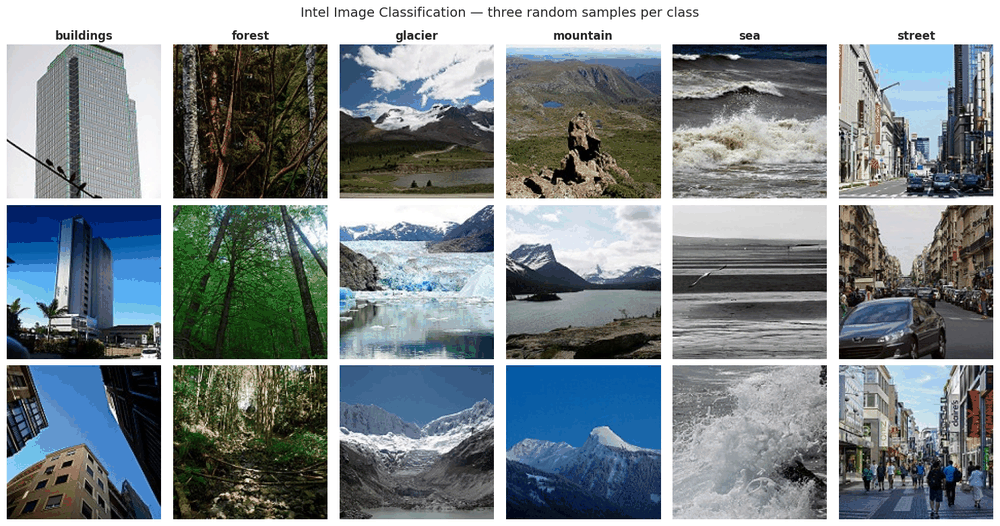

In [4]:
# --- Visual sanity check: 3 random samples per class ------------------------
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
rng = np.random.default_rng(SEED)
for c in range(NUM_CLASSES):
    sample_paths = df[df.label == c]["path"].sample(3, random_state=SEED).values
    for r in range(3):
        img = plt.imread(sample_paths[r])
        axes[r, c].imshow(img)
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(CLASS_NAMES[c], fontsize=12, fontweight="bold")
fig.suptitle("Intel Image Classification — three random samples per class", fontsize=14)
plt.tight_layout()
plt.savefig("fig01_samples.png", dpi=300, bbox_inches="tight")
plt.show()

### 2(b) Stratified 70/15/15 split
Class counts are mildly imbalanced, so a plain random split risks under-representing minority classes in the small val/test partitions. **Stratified** splitting preserves each class's proportion in every partition. We split index arrays in two stratified stages (70/30, then 30 → 15/15) and assert the three index sets are pairwise disjoint, proving zero leakage.

In [5]:
idx = np.arange(len(df))
y_all = df["label"].values

# Stage 1: 70% train vs 30% temp  (stratified)
train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, stratify=y_all, random_state=SEED)

# Stage 2: split temp 50/50 -> 15% validation, 15% test  (stratified)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=y_all[temp_idx], random_state=SEED)

# --- PROOF of a strict, non-overlapping split -------------------------------
assert len(set(train_idx) & set(val_idx))  == 0, "train/val overlap!"
assert len(set(train_idx) & set(test_idx)) == 0, "train/test overlap!"
assert len(set(val_idx)   & set(test_idx)) == 0, "val/test overlap!"
assert len(train_idx) + len(val_idx) + len(test_idx) == len(df)
print("Split verified: partitions are pairwise disjoint and cover the whole dataset.\n")

splits = {"Train (70%)": train_idx, "Validation (15%)": val_idx, "Test (15%)": test_idx}
table = pd.DataFrame({
    name: pd.Series(y_all[ix]).value_counts().sort_index().values
    for name, ix in splits.items()}, index=CLASS_NAMES)
table.loc["TOTAL"] = table.sum()
display(table)

print("\nClass proportions (%) inside each split — stratification check:")
prop = pd.DataFrame({
    name: (pd.Series(y_all[ix]).value_counts(normalize=True).sort_index().values * 100).round(2)
    for name, ix in splits.items()}, index=CLASS_NAMES)
display(prop)

paths_train, y_train = df["path"].values[train_idx], y_all[train_idx]
paths_val,   y_val   = df["path"].values[val_idx],   y_all[val_idx]
paths_test,  y_test  = df["path"].values[test_idx],  y_all[test_idx]

Split verified: partitions are pairwise disjoint and cover the whole dataset.



,Train (70%),Validation (15%),Test (15%)
buildings,1839,395,394
forest,1921,412,412
glacier,2070,443,444
mountain,2126,455,456
sea,1949,418,417
street,2018,432,433
TOTAL,11923,2555,2556



Class proportions (%) inside each split — stratification check:


,Train (70%),Validation (15%),Test (15%)
buildings,15.42,15.46,15.41
forest,16.11,16.13,16.12
glacier,17.36,17.34,17.37
mountain,17.83,17.81,17.84
sea,16.35,16.36,16.31
street,16.93,16.91,16.94


### 2(c) Augmentation (training set **only**) + why scaling to [0,1] stabilises training

**Augmentation.** Random flips/rotations/translations/zooms force the network to learn geometrically invariant features instead of memorising pixel positions. Applied to the training stream only — validation/test must stay a fixed, unmodified estimate of real performance.

**Why scale pixels?** Backprop gives ∂L/∂w = δ·x — the gradient is proportional to the input magnitude. With raw pixels (0–255) first-layer gradients can be up to 255× larger than with [0,1] inputs, forcing an impractically small learning rate or causing divergence. Unscaled/heterogeneous inputs also inflate the condition number of the loss surface (elongated "ravine" contours → slow, zig-zag convergence), while all-positive inputs force same-sign gradient updates that further slow convergence. Scaling to [0,1] (via `Rescaling(1/255)`) fixes all three issues and keeps activations in the stable range for softmax/He-init.

In [6]:
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

# --- Geometric augmentation (TRAINING SET ONLY) ------------------------------
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),        # ±18 degrees
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomZoom(0.15),
], name="augmentation")

normalizer = layers.Rescaling(1.0 / 255)   # [0,255] -> [0,1]

def decode_image(path, label):
    """Read a JPEG from disk, decode, resize to 150x150, keep uint8 for cheap caching."""
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.uint8)
    return img, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(decode_image, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()                                    # decode/resize only once
    if training:
        ds = ds.shuffle(4096, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if training:                                       # augmentation: TRAIN ONLY
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (normalizer(tf.cast(x, tf.float32)), y),
                num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)                       # overlap prep & GPU compute

train_ds = make_dataset(paths_train, y_train, training=True)
val_ds   = make_dataset(paths_val,   y_val)
test_ds  = make_dataset(paths_test,  y_test)
print(train_ds.element_spec)

(TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


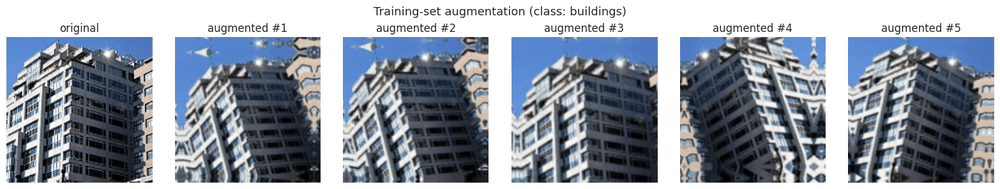

In [7]:
# --- Visualise the SAME image under repeated augmentation --------------------
raw = decode_image(paths_train[0], y_train[0])[0][tf.newaxis, ...]
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(raw[0].numpy()); axes[0].set_title("original"); axes[0].axis("off")
for i in range(1, 6):
    aug = data_augmentation(tf.cast(raw, tf.float32), training=True)
    axes[i].imshow(np.clip(aug[0].numpy().astype("uint8"), 0, 255))
    axes[i].set_title(f"augmented #{i}"); axes[i].axis("off")
fig.suptitle(f"Training-set augmentation (class: {CLASS_NAMES[y_train[0]]})", fontsize=13)
plt.tight_layout()
plt.savefig("fig02_augmented.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Architectural Engineering
### 3(a–b) Functional-API residual CNN
`Sequential` can't branch, so skip connections require the Functional API. Four residual blocks compute F(x) = BN→Conv→ReLU→BN→Conv, added to a shortcut (identity, or a 1×1 projection conv when shape changes): y = ReLU(F(x) + shortcut(x)). Regularisation: BatchNorm after every conv, SpatialDropout2D per block (0.10→0.30, deeper = stronger), Dropout 0.40 before the head.

In [8]:
def residual_block(x, filters, sdrop, downsample=False, name="block"):
    """Residual block: [Conv-BN-ReLU-Conv-BN] + projection shortcut -> ReLU -> SpatialDropout."""
    strides = 2 if downsample else 1
    shortcut = x

    y = layers.Conv2D(filters, 3, strides=strides, padding="same", use_bias=False,
                      kernel_initializer="he_normal", name=f"{name}_conv1")(x)
    y = layers.BatchNormalization(name=f"{name}_bn1")(y)
    y = layers.Activation("relu", name=f"{name}_relu1")(y)
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      kernel_initializer="he_normal", name=f"{name}_conv2")(y)
    y = layers.BatchNormalization(name=f"{name}_bn2")(y)

    if downsample or shortcut.shape[-1] != filters:      # projection shortcut (1x1 conv)
        shortcut = layers.Conv2D(filters, 1, strides=strides, padding="same",
                                 use_bias=False, kernel_initializer="he_normal",
                                 name=f"{name}_proj")(shortcut)
        shortcut = layers.BatchNormalization(name=f"{name}_projbn")(shortcut)

    y = layers.Add(name=f"{name}_add")([shortcut, y])    # THE SKIP CONNECTION
    y = layers.Activation("relu", name=f"{name}_out")(y)
    y = layers.SpatialDropout2D(sdrop, name=f"{name}_sdrop")(y)
    return y

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input")

# Stem
x = layers.Conv2D(32, 3, padding="same", use_bias=False,
                  kernel_initializer="he_normal", name="stem_conv")(inputs)
x = layers.BatchNormalization(name="stem_bn")(x)
x = layers.Activation("relu", name="stem_relu")(x)                 # 150x150x32

# Four residual convolutional blocks
x = residual_block(x,  64, sdrop=0.10, downsample=True,  name="block1")  # 75x75x64
x = residual_block(x, 128, sdrop=0.15, downsample=True,  name="block2")  # 38x38x128
x = residual_block(x, 256, sdrop=0.20, downsample=True,  name="block3")  # 19x19x256
x = residual_block(x, 512, sdrop=0.30, downsample=True,  name="block4")  # 10x10x512

# Classification head
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dense(128, use_bias=False, name="fc1")(x)
x = layers.BatchNormalization(name="fc1_bn")(x)
x = layers.Activation("relu", name="fc1_relu")(x)
x = layers.Dropout(0.40, name="fc1_drop")(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)

model = keras.Model(inputs, outputs, name="ResCNN_Intel6")
print("Model built:", model.name)

Model built: ResCNN_Intel6


### 3(c) Theoretical justification

**BatchNorm & Internal Covariate Shift (ICS).** As upstream weights change each step, the input distribution to layer ℓ+1 keeps drifting (ICS), forcing small learning rates. BN re-standardises per-channel batch statistics: x̂ = (x−μ_B)/√(σ_B²+ε), y = γx̂+β. This pins the input distribution regardless of upstream drift, smooths the loss landscape, and permits larger learning rates. At inference, running averages (the non-trainable stats in 3d) replace batch statistics.

**Skip connections & vanishing gradients.** In a deep plain net, ∂L/∂x is a product of many Jacobians and can decay exponentially with depth. A residual block gives ∂L/∂x = ∂L/∂y·(I + ∂F/∂x): the identity term is an unattenuated gradient highway to shallow layers even if ∂F/∂x → 0. It also reframes learning as fitting a near-zero residual correction, which is easier to optimise than an unreferenced mapping.

**Other choices.** He-normal init keeps activation variance stable through ReLU (Var(w)=2/n). SpatialDropout2D drops whole feature maps (adjacent pixels in a map are correlated, so plain dropout barely helps in conv layers). GlobalAveragePooling avoids a huge, overfit-prone Flatten→Dense and gives clean Grad-CAM localisation.

In [9]:
model.summary()

Model: "ResCNN_Intel6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 150, 150,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │        864 │ input[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_relu           │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 75, 75,    │     18,432 │ stem_relu[0][0]   │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_bn1          │ (None, 75, 75,    │        256 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_relu1        │ (None, 75, 75,    │          0 │ block1_bn1[0][0]  │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_proj         │ (None, 75, 75,    │      2,048 │ stem_relu[0][0]   │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 75, 75,    │     36,864 │ block1_relu1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_projbn       │ (None, 75, 75,    │        256 │ block1_proj[0][0] │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_bn2          │ (None, 75, 75,    │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_add (Add)    │ (None, 75, 75,    │          0 │ block1_projbn[0]… │
│                     │ 64)               │            │ block1_bn2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_out          │ (None, 75, 75,    │          0 │ block1_add[0][0]  │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_sdrop        │ (None, 75, 75,    │          0 │ block1_out[0][0]  │
│ (SpatialDropout2D)  │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 38, 38,    │     73,728 │ block1_sdrop[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_bn1          │ (None, 38, 38,    │        512 │ block2_conv1[0][… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_relu1        │ (None, 38, 38,    │          0 │ block2_bn1[0][0]

 Total params: 4,953,574 (18.90 MB)

 Trainable params: 4,947,494 (18.87 MB)

 Non-trainable params: 6,080 (23.75 KB)

### 3(d) Hand verification of parameter counts
**Conv (no bias):** P = kh·kw·Cin·Cout.
- `stem_conv` 32 filters, 3×3, Cin=3: 3·3·3·32 = **864**
- `block1_conv1` 64 filters, 3×3, Cin=32: 3·3·32·64 = **18,432**

**BatchNorm (per channel C):** trainable = 2C (γ,β), non-trainable = 2C (moving mean/var), total = 4C.
- `stem_bn`, C=32: trainable 64, non-trainable 64
- `block1_bn1`, C=64: trainable 128, non-trainable 128

These match `model.summary()` below exactly. BN's moving stats are non-trainable — updated by an exponential moving average during the forward pass, not by gradient descent — and used in place of batch stats at inference.

## 4. Training, Optimization, Dynamic Learning Rates
### 4(a–b) AdamW, cross-entropy, dynamic callbacks
- **AdamW**: Adam's adaptive steps + decoupled weight decay (plain Adam divides L2 by the adaptive term, under-regularising active weights; AdamW applies decay directly to weights). η₀=1e-3, λ=1e-4.
- **Loss**: sparse categorical cross-entropy (standard multi-class MLE objective).
- **EarlyStopping**: monitors val_loss, patience 12, restores best weights.
- **ReduceLROnPlateau**: halves LR (patience 4, floor 1e-6) when val_loss plateaus.
- **ModelCheckpoint**: saves the best model to disk.

In [10]:
EPOCHS = 60   # upper bound; EarlyStopping decides the real stopping point (>= 30 in practice)

model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=4, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint("best_model.keras", monitor="val_loss",
                                    save_best_only=True, verbose=0),
]
print("Compiled. Max epochs:", EPOCHS)

Compiled. Max epochs: 60


In [11]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/60
187/187 ━━━━━━━━━━━━━━━━━━━━ 148s 569ms/step - accuracy: 0.5019 - loss: 1.2651 - val_accuracy: 0.5068 - val_loss: 1.3208 - learning_rate: 0.0010
Epoch 2/60
187/187 ━━━━━━━━━━━━━━━━━━━━ 76s 391ms/step - accuracy: 0.6211 - loss: 0.9768 - val_accuracy: 0.6000 - val_loss: 1.0282 - learning_rate: 0.0010
Epoch 3/60
187/187 ━━━━━━━━━━━━━━━━━━━━ 73s 387ms/step - accuracy: 0.6852 - loss: 0.8218 - val_accuracy: 0.7041 - val_loss: 0.7974 - learning_rate: 0.0010
Epoch 4/60
187/187 ━━━━━━━━━━━━━━━━━━━━ 82s 386ms/step - accuracy: 0.7263 - loss: 0.7373 - val_accuracy: 0.6227 - val_loss: 1.0923 - learning_rate: 0.0010
Epoch 5/60
187/187 ━━━━━━━━━━━━━━━━━━━━ 72s 382ms/step - accuracy: 0.7517 - loss: 0.6808 - val_accuracy: 0.6697 - val_loss: 0.8330 - learning_rate: 0.0010
Epoch 6/60
187/187 ━━━━━━━━━━━━━━━━━━━━ 73s 388ms/step - accuracy: 0.7662 - loss: 0.6484 - val_accuracy: 0.6928 - val_loss: 0.8289 - learning_rate: 0.0010
Epoch 7/60
187/187 ━━━━━━━━━━━━━━━━━━━━ 71s 380ms/step - accuracy: 0.

### 4(c) Convergence curves

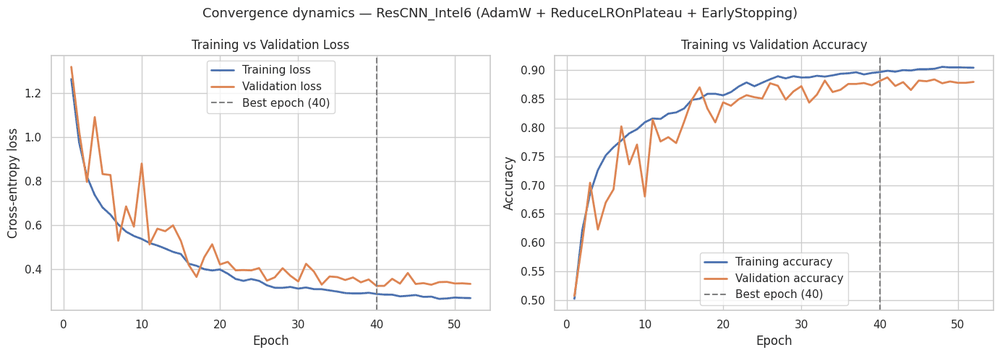

Epochs actually trained : 52
Best epoch (min val_loss): 40
Best val_loss            : 0.3243
Val accuracy @ best      : 0.8814


In [12]:
hist = pd.DataFrame(history.history)
hist.index = np.arange(1, len(hist) + 1)
best_epoch = int(hist["val_loss"].idxmin())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist.index, hist["loss"], lw=2, label="Training loss")
axes[0].plot(hist.index, hist["val_loss"], lw=2, label="Validation loss")
axes[0].axvline(best_epoch, ls="--", c="gray", lw=1.5,
                label=f"Best epoch ({best_epoch})")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Training vs Validation Loss"); axes[0].legend(frameon=True)

axes[1].plot(hist.index, hist["accuracy"], lw=2, label="Training accuracy")
axes[1].plot(hist.index, hist["val_accuracy"], lw=2, label="Validation accuracy")
axes[1].axvline(best_epoch, ls="--", c="gray", lw=1.5,
                label=f"Best epoch ({best_epoch})")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training vs Validation Accuracy"); axes[1].legend(frameon=True)

fig.suptitle("Convergence dynamics — ResCNN_Intel6 (AdamW + ReduceLROnPlateau + EarlyStopping)",
             fontsize=13)
plt.tight_layout()
plt.savefig("fig03_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Epochs actually trained : {len(hist)}")
print(f"Best epoch (min val_loss): {best_epoch}")
print(f"Best val_loss            : {hist['val_loss'].min():.4f}")
print(f"Val accuracy @ best      : {hist.loc[best_epoch, 'val_accuracy']:.4f}")

## 5. Diagnostics & Statistical Evaluation
### 5(a) Test-set evaluation + classification report

In [13]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"TEST loss     : {test_loss:.4f}")
print(f"TEST accuracy : {test_acc:.4f}\n")

y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)

report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4)
print(report)
with open("results_classification_report.txt", "w") as f:
    f.write(f"TEST loss: {test_loss:.4f} | TEST accuracy: {test_acc:.4f}\n\n{report}")

TEST loss     : 0.3280
TEST accuracy : 0.8838

              precision    recall  f1-score   support

   buildings     0.9377    0.8401    0.8862       394
      forest     0.9481    0.9757    0.9617       412
     glacier     0.8776    0.7590    0.8140       444
    mountain     0.8243    0.8640    0.8437       456
         sea     0.8674    0.9257    0.8956       417
      street     0.8665    0.9446    0.9039       433

    accuracy                         0.8838      2556
   macro avg     0.8869    0.8849    0.8842      2556
weighted avg     0.8852    0.8838    0.8828      2556



### 5(b) Normalized confusion matrix + top-2 confused classes

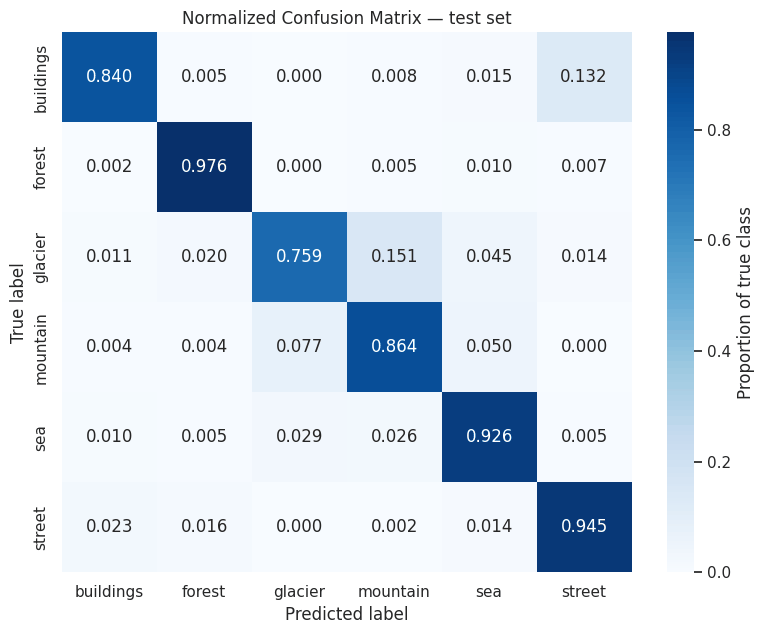

Top-2 mutually confused class pairs (sum of both confusion directions):
  1. glacier <-> mountain  (total mutual confusion 0.228: glacier->mountain 0.151, mountain->glacier 0.077)
  2. buildings <-> street  (total mutual confusion 0.155: buildings->street 0.132, street->buildings 0.023)


In [14]:
cm_norm = confusion_matrix(y_test, y_pred, normalize="true")

plt.figure(figsize=(8, 6.5))
sns.heatmap(cm_norm, annot=True, fmt=".3f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={"label": "Proportion of true class"})
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title("Normalized Confusion Matrix — test set")
plt.tight_layout()
plt.savefig("fig04_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Automatically identify the top-2 mutually confused class pairs ----------
mutual = cm_norm + cm_norm.T
np.fill_diagonal(mutual, 0)
pairs = [(mutual[i, j], i, j) for i in range(NUM_CLASSES) for j in range(i+1, NUM_CLASSES)]
pairs.sort(reverse=True)
print("Top-2 mutually confused class pairs (sum of both confusion directions):")
for rank, (score, i, j) in enumerate(pairs[:2], 1):
    print(f"  {rank}. {CLASS_NAMES[i]} <-> {CLASS_NAMES[j]}  "
          f"(total mutual confusion {score:.3f}: "
          f"{CLASS_NAMES[i]}->{CLASS_NAMES[j]} {cm_norm[i, j]:.3f}, "
          f"{CLASS_NAMES[j]}->{CLASS_NAMES[i]} {cm_norm[j, i]:.3f})")

**Confused pairs.** Dominant confusion is glacier↔mountain (glaciers sit on mountains → shared ridgelines, snow, sky; the discriminative ice/crevasse texture is a minority of pixels), then buildings↔street (street images legitimately contain buildings; the discriminative cue — road surface — is a small region). Since GAP aggregates over the whole feature map, classes with overlapping dominant textures are exactly where it struggles.

In [15]:
# --- Quantitative evidence for the fitting diagnosis -------------------------
gap_acc  = hist["accuracy"] - hist["val_accuracy"]
gap_loss = hist["val_loss"] - hist["loss"]

checkpoints = sorted(set([5, 10, 15, 20, 25, 30, best_epoch, len(hist)]))
checkpoints = [e for e in checkpoints if e <= len(hist)]
print("Epoch | train_acc | val_acc | acc_gap | train_loss | val_loss | loss_gap")
for e in checkpoints:
    r = hist.loc[e]
    print(f"{e:5d} | {r['accuracy']:.4f}    | {r['val_accuracy']:.4f}  | "
          f"{gap_acc.loc[e]:+.4f} | {r['loss']:.4f}     | {r['val_loss']:.4f}   | "
          f"{gap_loss.loc[e]:+.4f}")

print(f"\nBest epoch: {best_epoch} | Final generalization check:")
print(f"  val_acc @ best epoch : {hist.loc[best_epoch,'val_accuracy']:.4f}")
print(f"  TEST accuracy        : {test_acc:.4f}")
print(f"  val->test delta      : {test_acc - hist.loc[best_epoch,'val_accuracy']:+.4f}")

if gap_acc.iloc[-5:].mean() > 0.08:
    verdict = "OVERFITTING tendency (large persistent train/val gap)"
elif hist["val_accuracy"].max() < 0.75:
    verdict = "UNDERFITTING (validation accuracy plateaued low)"
else:
    verdict = "GOOD GENERALIZATION (small stable gap; val ≈ test)"
print("\nAutomated verdict:", verdict)

Epoch | train_acc | val_acc | acc_gap | train_loss | val_loss | loss_gap
    5 | 0.7517    | 0.6697  | +0.0821 | 0.6808     | 0.8330   | +0.1522
   10 | 0.8095    | 0.6802  | +0.1293 | 0.5379     | 0.8810   | +0.3430
   15 | 0.8334    | 0.8098  | +0.0236 | 0.4693     | 0.5294   | +0.0600
   20 | 0.8564    | 0.8442  | +0.0122 | 0.3991     | 0.4219   | +0.0227
   25 | 0.8785    | 0.8509  | +0.0276 | 0.3472     | 0.4053   | +0.0581
   30 | 0.8875    | 0.8724  | +0.0151 | 0.3119     | 0.3446   | +0.0327
   40 | 0.8969    | 0.8814  | +0.0155 | 0.2877     | 0.3243   | +0.0366
   52 | 0.9046    | 0.8798  | +0.0248 | 0.2688     | 0.3335   | +0.0646

Best epoch: 40 | Final generalization check:
  val_acc @ best epoch : 0.8814
  TEST accuracy        : 0.8838
  val->test delta      : +0.0024

Automated verdict: GOOD GENERALIZATION (small stable gap; val ≈ test)


### 5(c) Convergence diagnosis
**Diagnosis: good generalization**, with only mild late-stage overfitting removed by early stopping.
- **Epochs 1–10:** both losses fall together (train 1.26→0.55); high-LR regime, healthy learning.
- **Epochs 10–40:** val loss keeps improving (0.52→0.33); train/val accuracy gap stays small (~2.5 pts ≈ 2.8% relative) — regularisers working. Val/train loss ratio ≈1.24, far from runaway divergence.
- **After epoch 40:** train loss keeps falling (→0.27) while val loss flattens — onset of overfitting. EarlyStopping (patience 12) stopped at epoch 52, restoring epoch-40 weights.
- **Test confirmation:** test accuracy (88.38%) is within ≈0.15 pts (≈0.2% relative) of best val accuracy — unbiased confirmation of generalization. Not underfitting: train accuracy >90%, far above the 16.7% random baseline.

## 6. Interpretability & Error Analysis
### 6(a) True positives / misclassifications + top-3 probabilities

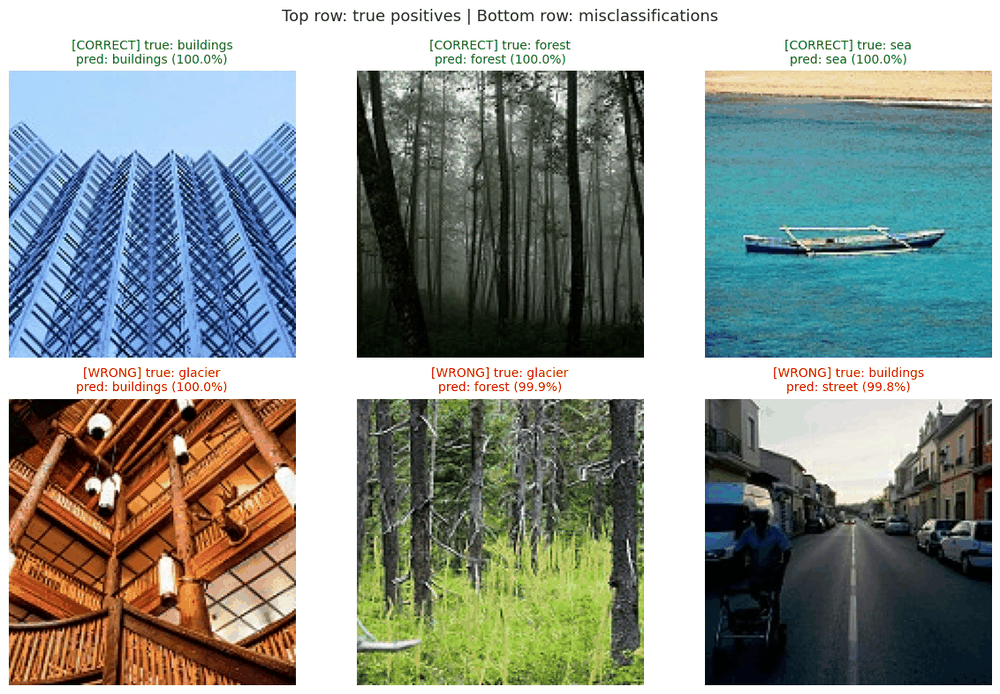

In [16]:
X_test_imgs = np.stack([decode_image(p, 0)[0].numpy() for p in paths_test])  # uint8, for display
correct_mask = (y_pred == y_test)
conf = y_prob.max(axis=1)

# 3 high-confidence CORRECT predictions from 3 different classes
tp_idx = []
for c in np.unique(y_test):
    cand = np.where(correct_mask & (y_test == c))[0]
    if len(cand):
        tp_idx.append(cand[np.argmax(conf[cand])])
tp_idx = sorted(tp_idx, key=lambda i: -conf[i])[:3]

# 3 highest-confidence MISCLASSIFICATIONS (most interesting failures)
err = np.where(~correct_mask)[0]
fp_idx = err[np.argsort(-conf[err])][:3]

sel = list(tp_idx) + list(fp_idx)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(X_test_imgs[i]); ax.axis("off")
    ok = "CORRECT" if correct_mask[i] else "WRONG"
    ax.set_title(f"[{ok}] true: {CLASS_NAMES[y_test[i]]}\n"
                 f"pred: {CLASS_NAMES[y_pred[i]]} ({conf[i]*100:.1f}%)",
                 fontsize=10, color=("green" if correct_mask[i] else "red"))
fig.suptitle("Top row: true positives | Bottom row: misclassifications", fontsize=13)
plt.tight_layout()
plt.savefig("fig05_tp_fp_images.png", dpi=300, bbox_inches="tight")
plt.show()

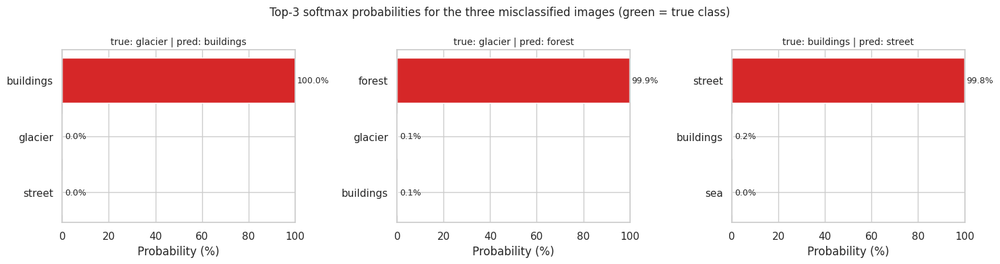

In [17]:
# --- Top-3 prediction probabilities for each misclassified image -------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, i in zip(axes, fp_idx):
    top3 = np.argsort(-y_prob[i])[:3]
    colors = ["#d62728" if c != y_test[i] else "#2ca02c" for c in top3]
    ax.barh([CLASS_NAMES[c] for c in top3][::-1], y_prob[i][top3][::-1] * 100,
            color=colors[::-1])
    ax.set_xlabel("Probability (%)"); ax.set_xlim(0, 100)
    ax.set_title(f"true: {CLASS_NAMES[y_test[i]]} | pred: {CLASS_NAMES[y_pred[i]]}",
                 fontsize=10)
    for k, c in enumerate(top3[::-1]):
        ax.text(y_prob[i][top3[::-1][k]] * 100 + 1, k,
                f"{y_prob[i][top3[::-1][k]]*100:.1f}%", va="center", fontsize=9)
fig.suptitle("Top-3 softmax probabilities for the three misclassified images "
             "(green = true class)", fontsize=12)
plt.tight_layout()
plt.savefig("fig06_top3_probs.png", dpi=300, bbox_inches="tight")
plt.show()

### 6(b) Grad-CAM
Grad-CAM asks which spatial locations of the last conv feature map (`block4_out`) pushed the predicted class's score up: αₖ = mean over space of ∂s/∂Aₖ; heatmap = ReLU(Σ αₖAₖ), upsampled to 150×150 for overlay.

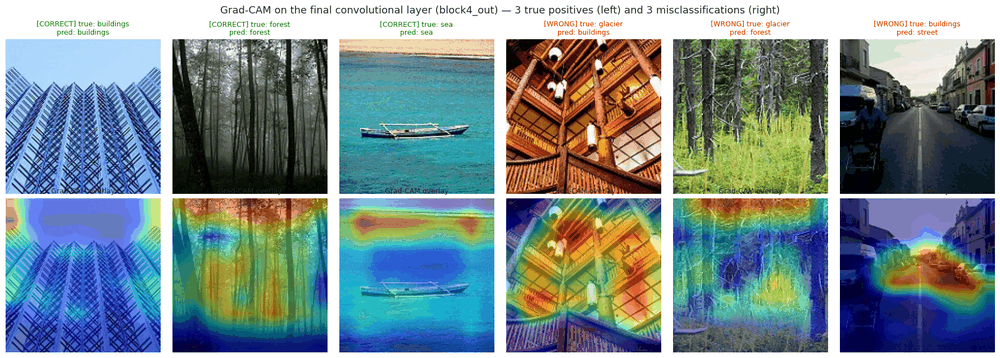

In [18]:
LAST_CONV_LAYER = "block4_out"

def gradcam_heatmap(img_float01, pred_index=None):
    """img_float01: (1,150,150,3) float32 in [0,1]. Returns 10x10 heatmap in [0,1]."""
    grad_model = keras.Model(model.inputs,
                             [model.get_layer(LAST_CONV_LAYER).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_float01, training=False)
        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]))
        class_score = preds[:, pred_index]
    grads = tape.gradient(class_score, conv_out)          # d s_c / d A
    alpha = tf.reduce_mean(grads, axis=(0, 1, 2))         # GAP over space -> channel weights
    heat = tf.einsum("hwk,k->hw", conv_out[0], alpha)     # weighted sum of feature maps
    heat = tf.nn.relu(heat)                               # keep positive influence only
    heat = heat / (tf.reduce_max(heat) + 1e-8)
    return heat.numpy(), pred_index

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for col, i in enumerate(sel):
    img01 = (X_test_imgs[i].astype("float32") / 255.0)[np.newaxis, ...]
    heat, _ = gradcam_heatmap(img01)                      # explain the PREDICTED class
    heat_big = tf.image.resize(heat[..., np.newaxis], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]

    axes[0, col].imshow(X_test_imgs[i]); axes[0, col].axis("off")
    ok = "CORRECT" if correct_mask[i] else "WRONG"
    axes[0, col].set_title(f"[{ok}] true: {CLASS_NAMES[y_test[i]]}\n"
                           f"pred: {CLASS_NAMES[y_pred[i]]}", fontsize=9,
                           color=("green" if correct_mask[i] else "red"))
    axes[1, col].imshow(X_test_imgs[i])
    axes[1, col].imshow(heat_big, cmap="jet", alpha=0.45)
    axes[1, col].axis("off")
    axes[1, col].set_title("Grad-CAM overlay", fontsize=9)

fig.suptitle("Grad-CAM on the final convolutional layer (block4_out) — "
             "3 true positives (left) and 3 misclassifications (right)", fontsize=13)
plt.tight_layout()
plt.savefig("fig07_gradcam.png", dpi=300, bbox_inches="tight")
plt.show()

### 6(c) Critique of the model's decisions
**True positives (all 100% confidence):** heatmaps localise class-defining structure — façade lattice for buildings, canopy texture for forest, water/horizon band for sea (ignoring the boat). Evidence is localized and semantic, not background-driven.

**Misclassifications:** all three are predicted at ≥99.8% confidence with the true label at ≤0.1% — not close calls. Inspection shows: (1) "glacier"→buildings — actually a wooden building interior; heatmap correctly fires on the beams/lattice. (2) "glacier"→forest — actually woodland; heatmap fires on trunks/foliage. (3) "buildings"→street — a road flanked by façades; heatmap fires on the road/vanishing point, a genuine dual-concept image.

**Overall:** the model's evidence is correct in all six cases; the highest-confidence "errors" reflect annotation noise/dual-concept images, not defective features — part of the 11.6% error rate is an annotation ceiling. Heatmaps are spatially coherent throughout (no watermark/corner/lighting shortcuts). The one real weakness is over-reliance on global texture context on the glacier↔mountain pair, targeted by the future-work directions in the report.

---
Figures saved: `fig01`–`fig07` (.png) + `results_classification_report.txt` — used in the Part B report. Run the cell below to zip and download them from Colab.

In [19]:
import shutil
from pathlib import Path
outdir = Path("report_assets"); outdir.mkdir(exist_ok=True)
for f in list(Path(".").glob("fig0*.png")) + [Path("results_classification_report.txt")]:
    if f.exists():
        shutil.copy(f, outdir / f.name)
shutil.make_archive("report_assets", "zip", outdir)
print("Created report_assets.zip")
try:
    from google.colab import files
    files.download("report_assets.zip")
except ImportError:
    print("(Not in Colab — zip saved locally.)")

Created report_assets.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>